# Practical 2: Dimensionality Reduction with PCA and LDA

**Subject:** Machine Learning  |  **Type:** Unsupervised and supervised dimensionality reduction

## Aim
Make use of the dimensionality reduction process using **PCA** and **LDA** on a suitable open-access high-dimensional dataset, and observe the influence of feature reduction on **model performance** and **computational efficiency**.

## Dataset
**Breast Cancer Wisconsin (Diagnostic)**: 569 samples, **30 numeric features**, 2 classes (malignant / benign). Built into scikit-learn (no download).

A second dataset, **Wine** (13 features, 3 classes), is used in Part B to show LDA with 2 components.

## Steps
1. Load data, split, standardise
2. Baseline classifier on all 30 features (accuracy and time)
3. PCA: explained variance, scree plot, choose components
4. LDA: supervised projection
5. Compare accuracy and time for all models
6. Visualise PCA vs LDA projections
7. Part B: Wine dataset with 2 components each

## Step 0: Import libraries

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

## Step 1: Load, split and scale

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target
print("Samples:", X.shape[0], "| Features:", X.shape[1])
print("Classes:", dict(zip(data.target_names, np.bincount(y))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only
X_test_s = scaler.transform(X_test)

Samples: 569 | Features: 30
Classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


**Why scale?** PCA maximises variance, so features with big numeric ranges (like `area`) would dominate. Standardising gives every feature equal weight.

## Step 2: Baseline model on all 30 features

In [3]:
def evaluate(name, A_tr, A_te, repeats=30):
    # Train a logistic regression, report accuracy and average training time.
    t0 = time.perf_counter()
    for _ in range(repeats):
        model = LogisticRegression(max_iter=2000).fit(A_tr, y_train)
    avg_time = (time.perf_counter() - t0) / repeats
    acc = accuracy_score(y_test, model.predict(A_te))
    return {"Model": name, "Features": A_tr.shape[1], "Accuracy": round(acc, 4),
            "Train time (ms)": round(avg_time * 1000, 3)}

results = [evaluate("Original (all features)", X_train_s, X_test_s)]
results[0]

{'Model': 'Original (all features)',
 'Features': 30,
 'Accuracy': 0.9825,
 'Train time (ms)': 3.315}

## Step 3: PCA (Principal Component Analysis)

PCA is **unsupervised**: it ignores the labels and finds new orthogonal axes (principal components) that capture the maximum variance.

PC1 explains 44.4% and PC2 explains 18.9% of the variance
Components needed for 95% variance: 10 | for 99%: 17 (out of 30)


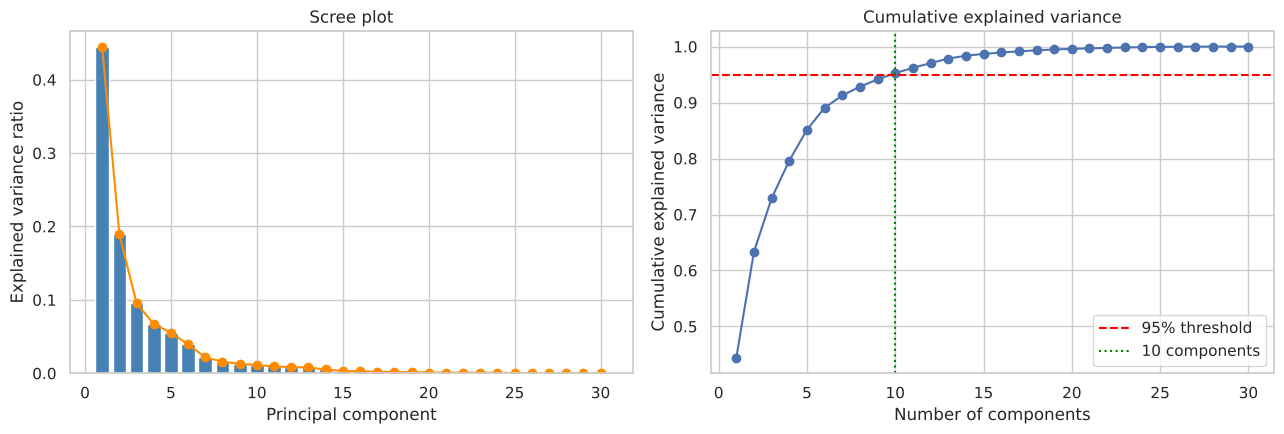

In [4]:
pca_full = PCA().fit(X_train_s)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

n95 = int(np.argmax(cum >= 0.95) + 1)
n99 = int(np.argmax(cum >= 0.99) + 1)
print("PC1 explains %.1f%% and PC2 explains %.1f%% of the variance" % (evr[0]*100, evr[1]*100))
print("Components needed for 95%% variance: %d | for 99%%: %d (out of 30)" % (n95, n99))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Scree plot
ax[0].bar(range(1, 31), evr, color="steelblue")
ax[0].plot(range(1, 31), evr, "o-", color="darkorange")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance ratio")
ax[0].set_title("Scree plot")

# Cumulative variance
ax[1].plot(range(1, 31), cum, "o-")
ax[1].axhline(0.95, color="red", ls="--", label="95% threshold")
ax[1].axvline(n95, color="green", ls=":", label=f"{n95} components")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative explained variance")
ax[1].set_title("Cumulative explained variance"); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read these graphs**
- **Scree plot:** each bar is the variance captured by one component. The first component is tallest and the bars drop quickly (the "elbow"), so only a few components matter.
- **Cumulative plot:** the red dashed line is 95%. The first x-value where the curve crosses it (the green dotted line) is the number of components to keep. Here the 30 features can be cut to about 10 while keeping 95% of the information.

### PCA with 2 components and with 95% variance

In [5]:
# (a) 2 components
pca2 = PCA(n_components=2).fit(X_train_s)
Xtr_p2, Xte_p2 = pca2.transform(X_train_s), pca2.transform(X_test_s)
results.append(evaluate("PCA (2 components)", Xtr_p2, Xte_p2))

# (b) components for 95% variance
pca95 = PCA(n_components=0.95).fit(X_train_s)
Xtr_p95, Xte_p95 = pca95.transform(X_train_s), pca95.transform(X_test_s)
results.append(evaluate(f"PCA ({pca95.n_components_} components, 95% var)", Xtr_p95, Xte_p95))
print("Components kept for 95%:", pca95.n_components_)

Components kept for 95%: 10


## Step 4: LDA (Linear Discriminant Analysis)

LDA is **supervised**: it uses the class labels and finds the axes that **maximise the distance between class means while minimising the spread inside each class**. The maximum number of components is `min(n_features, n_classes - 1)`. With 2 classes, that is **1** component.

In [6]:
lda = LDA(n_components=1).fit(X_train_s, y_train)
Xtr_l, Xte_l = lda.transform(X_train_s), lda.transform(X_test_s)
results.append(evaluate("LDA (1 component)", Xtr_l, Xte_l))
Xtr_l.shape

(455, 1)

## Step 5: Compare performance and computational efficiency

In [7]:
res_df = pd.DataFrame(results)
res_df

,Model,Features,Accuracy,Train time (ms)
0,Original (all features),30,0.9825,3.315
1,PCA (2 components),2,0.9474,2.129
2,"PCA (10 components, 95% var)",10,0.9737,3.032
3,LDA (1 component),1,0.9737,1.925


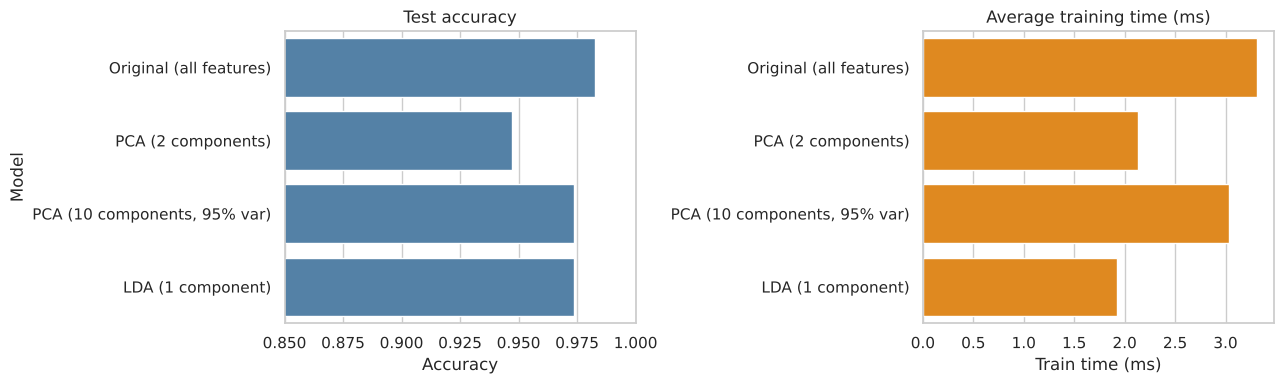

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=res_df, y="Model", x="Accuracy", ax=ax[0], color="steelblue")
ax[0].set_xlim(0.85, 1.0); ax[0].set_title("Test accuracy")
sns.barplot(data=res_df, y="Model", x="Train time (ms)", ax=ax[1], color="darkorange")
ax[1].set_title("Average training time (ms)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretation:** accuracy stays close to the baseline (about 98%) even after cutting from 30 features to 10, 2 or 1: PCA with 10 components and LDA with 1 component lose under 1 point, and PCA with 2 components loses about 3 to 4 points. So most of the information was redundant (the features are highly correlated).

**About the time column:** this dataset is tiny (455 training rows), so training takes only a few milliseconds and the differences are mostly noise; PCA with 10 components can even look slightly slower. Computational saving from fewer features shows up on large datasets, and also in prediction time, memory and storage. Be honest about this in the viva: say the saving is theoretical here because the data is small. Your exact numbers will vary between runs and machines.

### Accuracy vs number of PCA components

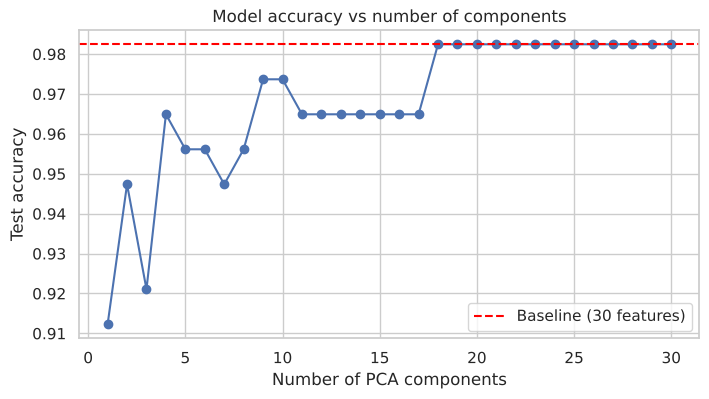

In [9]:
ks = list(range(1, 31))
accs = []
for k in ks:
    p = PCA(n_components=k).fit(X_train_s)
    m = LogisticRegression(max_iter=2000).fit(p.transform(X_train_s), y_train)
    accs.append(accuracy_score(y_test, m.predict(p.transform(X_test_s))))

plt.figure(figsize=(8, 4))
plt.plot(ks, accs, "o-")
plt.axhline(res_df.loc[0, "Accuracy"], color="red", ls="--", label="Baseline (30 features)")
plt.xlabel("Number of PCA components"); plt.ylabel("Test accuracy"); plt.legend()
plt.title("Model accuracy vs number of components"); plt.show()

**How to read this:** accuracy rises quickly with the first few components and then plateaus near the baseline. After that point, extra components add computation but no accuracy.

## Step 6: Visualise PCA vs LDA projections

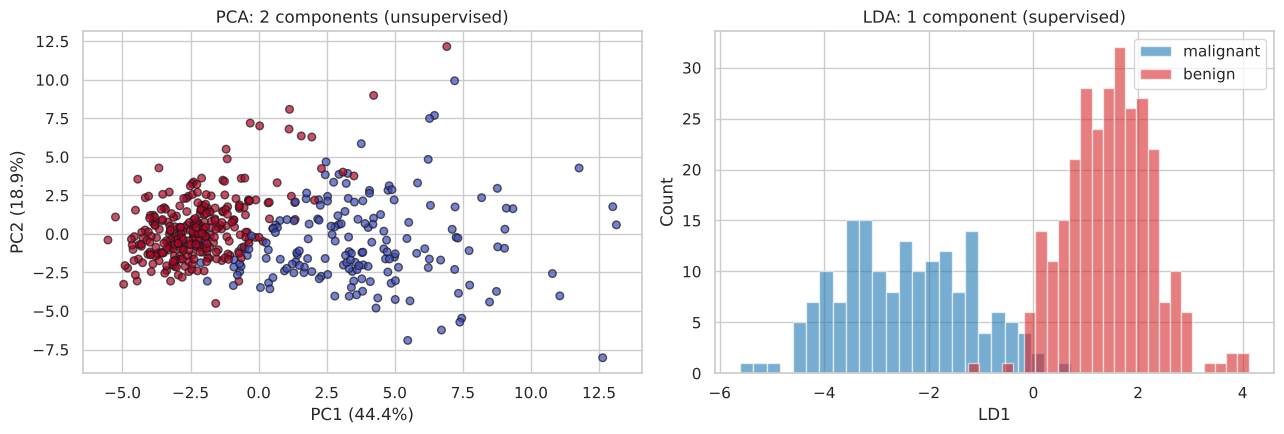

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# PCA scatter
sc = ax[0].scatter(Xtr_p2[:, 0], Xtr_p2[:, 1], c=y_train, cmap="coolwarm", alpha=0.7, edgecolor="k", s=30)
ax[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
ax[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
ax[0].set_title("PCA: 2 components (unsupervised)")

# LDA histogram (1 component)
for label, name, col in [(0, "malignant", "tab:blue"), (1, "benign", "tab:red")]:
    ax[1].hist(Xtr_l[y_train == label, 0], bins=25, alpha=0.6, label=name, color=col)
ax[1].set_xlabel("LD1"); ax[1].set_ylabel("Count")
ax[1].set_title("LDA: 1 component (supervised)"); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read these graphs**
- **PCA scatter:** each dot is a patient, coloured by class. PC1 is the direction of greatest variance, PC2 the next one (perpendicular). The two colours separate well even though PCA never saw the labels, which means class differences are a major source of variance.
- **LDA histogram:** because there are only 2 classes, LDA gives 1 axis (LD1). The two histograms are far apart with little overlap, which means LDA found an axis that cleanly separates the classes. The overlap region is where misclassifications occur.

## Part B: Wine dataset (3 classes) with 2 components each

With 3 classes LDA can produce **2** components (c - 1 = 2), so we can compare the 2-D plots directly.

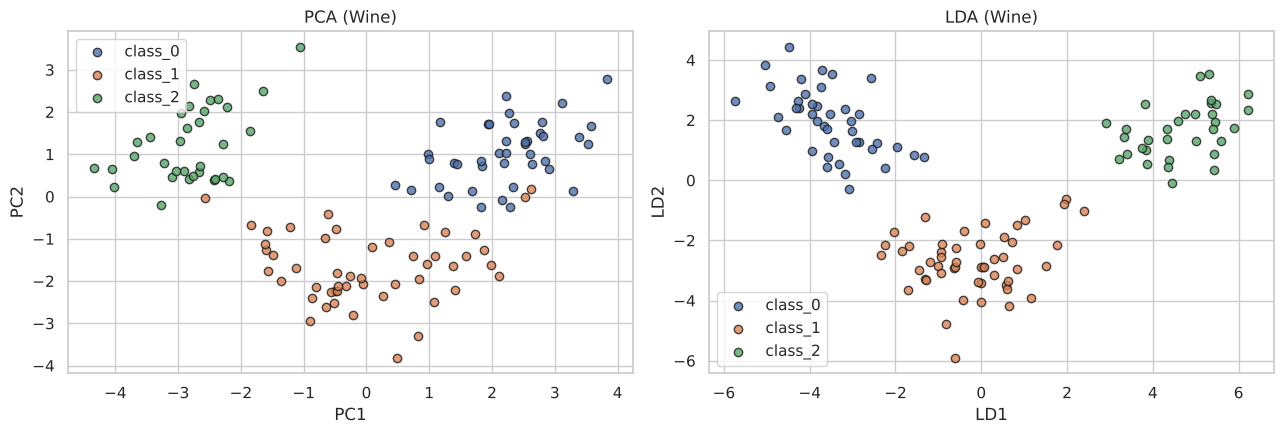

All 13 features    accuracy = 0.981
PCA 2              accuracy = 0.944
LDA 2              accuracy = 0.981


In [11]:
wine = load_wine()
Xw, yw = wine.data, wine.target
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.3, random_state=42, stratify=yw)
sw = StandardScaler().fit(Xw_tr)
Xw_tr, Xw_te = sw.transform(Xw_tr), sw.transform(Xw_te)

pw = PCA(n_components=2).fit(Xw_tr)
lw = LDA(n_components=2).fit(Xw_tr, yw_tr)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, proj, title in [(ax[0], pw.transform(Xw_tr), "PCA (Wine)"), (ax[1], lw.transform(Xw_tr), "LDA (Wine)")]:
    for cls in np.unique(yw_tr):
        a.scatter(proj[yw_tr == cls, 0], proj[yw_tr == cls, 1], label=wine.target_names[cls], alpha=0.8, edgecolor="k")
    a.set_title(title); a.legend()
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[1].set_xlabel("LD1"); ax[1].set_ylabel("LD2")
plt.tight_layout(); plt.show()

for name, tr, te in [("All 13 features", Xw_tr, Xw_te), ("PCA 2", pw.transform(Xw_tr), pw.transform(Xw_te)),
                     ("LDA 2", lw.transform(Xw_tr), lw.transform(Xw_te))]:
    m = LogisticRegression(max_iter=2000).fit(tr, yw_tr)
    print(f"{name:18s} accuracy = {accuracy_score(yw_te, m.predict(te)):.3f}")

**Interpretation:** LDA clusters are usually tighter and more clearly separated than PCA clusters, because LDA uses the labels to maximise class separation, whereas PCA only maximises total variance.

### Which original features drive PC1? (loadings)

In [12]:
loadings = pd.DataFrame(pca2.components_.T, index=data.feature_names, columns=["PC1", "PC2"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(8).round(3)

,PC1,PC2
mean concave points,0.261,-0.038
mean concavity,0.258,0.064
worst concave points,0.250,-0.009
mean compactness,0.242,0.144
worst perimeter,0.235,-0.204
worst concavity,0.230,0.101
mean perimeter,0.226,-0.220
worst radius,0.226,-0.224


## Result / Conclusion
- 30 features were reduced to 10 (PCA, 95% variance), 2 (PCA) or 1 (LDA). Accuracy stayed within about 1 point of the baseline for 10 components and LDA, and about 3 to 4 points lower for 2 PCA components.
- Fewer features give simpler models, less storage and 2-D visualisation. Training-time savings are not visible on this small dataset but matter on large data.
- LDA (supervised) gives better class separation per component than PCA (unsupervised).

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is dimensionality reduction? Why use it?**
Reducing the number of input features while keeping most of the information. It reduces computation, storage, noise and overfitting, helps visualisation and fights the curse of dimensionality.

**Q2. What is the curse of dimensionality?**
As the number of features grows, data becomes sparse, distances lose meaning and models need exponentially more data, so they overfit easily.

**Q3. What is PCA?**
Principal Component Analysis is an unsupervised technique that transforms correlated features into a smaller set of uncorrelated variables (principal components), ordered by how much variance they capture.

**Q4. Explain the steps of PCA.**
(1) Standardise the data. (2) Compute the covariance matrix. (3) Find eigenvalues and eigenvectors. (4) Sort eigenvectors by eigenvalue, largest first. (5) Select the top k. (6) Project the data onto them.

**Q5. What are eigenvalues and eigenvectors in PCA?**
An eigenvector is a direction (a principal component). Its eigenvalue says how much variance lies along that direction.

**Q6. Why must data be scaled before PCA?**
PCA maximises variance, so features with large units dominate. Scaling gives all features equal weight.

**Q7. What is LDA?**
Linear Discriminant Analysis is a supervised technique that finds axes that maximise separation between classes (between-class variance) while minimising spread inside each class (within-class variance).

**Q8. Difference between PCA and LDA?**
PCA is unsupervised and maximises total variance; it can give up to n_features components. LDA is supervised and maximises class separability; it gives at most (number of classes - 1) components.

**Q9. Why is the maximum number of LDA components c - 1?**
With c classes the c class means lie in a space of dimension at most c - 1, so there are only c - 1 useful discriminant directions. A binary problem gives 1 component.

**Q10. Is PCA feature selection?**
No. It is feature extraction: new features are created as combinations of the old ones. Feature selection keeps a subset of original features.

**Q11. How do you choose the number of components?**
Keep enough to explain about 95% of the variance (cumulative plot), use the scree-plot elbow, or choose by validation accuracy.

**Q12. Did performance fall after reduction? Why?**
Slightly or not at all, because some information is discarded but most of it was redundant. The trade-off is lower computation and a simpler model for a small accuracy change.

**Q13. Are principal components interpretable?**
Not easily. Each is a mix of all original features. The weights (loadings) are in `pca.components_`.

**Q14. What assumptions does LDA make?**
Features are normally distributed within each class, all classes share the same covariance matrix, and classes are linearly separable.

**Q15. Is PCA affected by outliers?**
Yes, because it relies on variance and the covariance matrix, so extreme points can pull the components.

**Q16. Are principal components correlated with each other?**
No. They are orthogonal (uncorrelated) by construction.

**Q17. What is explained variance ratio?**
The fraction of total variance captured by each component. They sum to 1 over all components.

**Q18. Can PCA be used for supervised problems?**
Yes, as a preprocessing step before a classifier, but PCA itself ignores labels, so the top components are not guaranteed to be the most predictive.

**Q19. What is the difference between LDA and logistic regression?**
Both give linear boundaries. LDA is generative (models each class as a Gaussian with shared covariance) and is also used for dimensionality reduction. Logistic regression is discriminative and models the probability directly.

**Q20. Give other dimensionality reduction methods.**
t-SNE, UMAP, Kernel PCA, Autoencoders, SVD, Factor Analysis, and feature selection methods (filter, wrapper, embedded).

## B. Questions about the graphs

**G1. What does the cumulative explained variance plot show?**
X-axis: number of components. Y-axis: share of total variance captured together. It rises steeply then flattens. About 10 components keep roughly 95% of the variance, so 30 features can be cut to about 10 with little loss.

**G2. What is the dashed line at 0.95?**
A threshold. The first x-value where the curve crosses it is the number of components to keep.

**G3. What is a scree plot and how do you use it?**
A plot of variance explained by each individual component. Look for the elbow where bars drop off and keep the components before it.

**G4. What do PC1 and PC2 on the scatter plot mean?**
PC1 is the direction of maximum variance in the data; PC2 is the next direction, perpendicular to PC1. Both are linear combinations of the original features.

**G5. The two classes are separated in the PCA scatter. Why, if PCA ignores labels?**
The classes differ strongly along the directions of highest variance, so even 2 components carry most of the class information. If the points overlapped heavily, 2 components would be insufficient.

**G6. Why does the LDA plot separate classes better than PCA?**
LDA uses labels and picks the axis maximising between-class distance relative to within-class spread. PCA only maximises total variance.

**G7. What does the LDA histogram overlap represent?**
The region where the two classes cannot be distinguished along LD1. Samples in that region are the likely misclassifications.

**G8. What does the accuracy-vs-components graph show?**
Accuracy rises quickly with the first few components and then plateaus near the baseline. More components after the plateau add cost but no benefit.

**G9. Why is the accuracy bar chart x-axis starting at 0.85?**
To zoom into small differences. Mention that this exaggerates differences, so read the numbers.

**G10. What does the loadings table tell you?**
Which original features contribute most to each principal component (large absolute value = strong influence).

## C. Code questions

**C1. Why `fit_transform` on train but only `transform` on test?**
To avoid data leakage. The mean and std must come from training data only.

**C2. What does `PCA(n_components=0.95)` do?**
It automatically keeps the smallest number of components whose cumulative explained variance is at least 95%.

**C3. Why does LDA need `y` in `fit` while PCA does not?**
LDA is supervised and uses class labels; PCA is unsupervised.

**C4. Why `stratify=y`?**
To keep the class proportions the same in train and test sets.